# EM for a very simple Gaussian process

This notebook builds up, one step at a time:

1. what a Gaussian process (GP) is,
2. how GP regression recovers a hidden function from noisy data,
3. how the **EM algorithm** learns the model's two variance parameters,
4. why the textbook formulas fail on a computer, and how to fix them,
5. how EM compares with simply handing the likelihood to an optimiser.

All the maths lives in `gp_em.py`; this notebook only calls it and plots. Open that file alongside.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

import gp_em

# One colour per thing, used consistently in every figure.
C_F = "#2a78d6"       # the hidden function f
C_Y = "#eb6834"       # the noisy observations y
C_POST = "#1baf7a"    # our estimate of f
C_STABLE = "#4a3aa7"  # stable (Cholesky) EM
C_NAIVE = "#e87ba4"   # naive (inverse) EM
C_REF = "#52514e"     # reference lines and markers
BLUES = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#2a78d6", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "figure.dpi": 110,
    "axes.edgecolor": "#c3c2b7", "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.titlelocation": "left", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "lines.linewidth": 2, "legend.frameon": False,
})

## 1. What a Gaussian process is

A GP is a probability distribution over *functions*. On a computer we only ever look at a function at a finite list of inputs $x_1,\dots,x_n$, and there the definition is simple:

$$f = \big(f(x_1),\dots,f(x_n)\big) \sim \mathcal N(0,\; s^2 K)$$

an ordinary multivariate Gaussian. Everything interesting is in the covariance matrix. We use the **RBF kernel**

$$K_{ij} = \exp\!\Big(-\frac{(x_i-x_j)^2}{2\ell^2}\Big)$$

which says: function values at nearby inputs are almost perfectly correlated, and values further apart than a few **lengthscales** $\ell$ are independent. That single statement is what makes draws from the GP smooth.

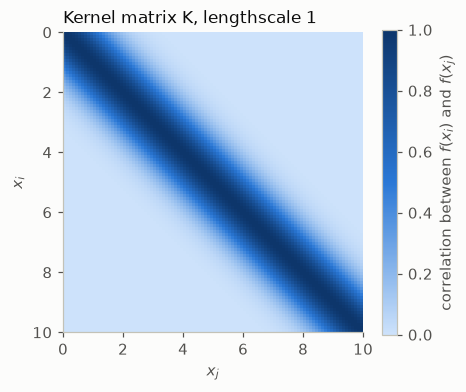

In [2]:
x_demo = np.linspace(0, 10, 100)
K_demo = gp_em.rbf_kernel(x_demo, x_demo, lengthscale=1.0)

fig, ax = plt.subplots(figsize=(4.4, 3.6))
im = ax.imshow(K_demo, cmap=BLUES, extent=[0, 10, 10, 0], vmin=0, vmax=1)
ax.grid(False)
ax.set(title="Kernel matrix K, lengthscale 1", xlabel="$x_j$", ylabel="$x_i$")
fig.colorbar(im, ax=ax, label="correlation between $f(x_i)$ and $f(x_j)$");

The bright band along the diagonal is "nearby points are correlated". Its width is the lengthscale.

To draw a random function we factor $K = LL^\top$ (a Cholesky factorisation) and compute $f = s\,Lz$ with $z$ standard normal. Below, five draws for each of three lengthscales. The other parameter, the **signal variance** $s^2$, just stretches the draws vertically.

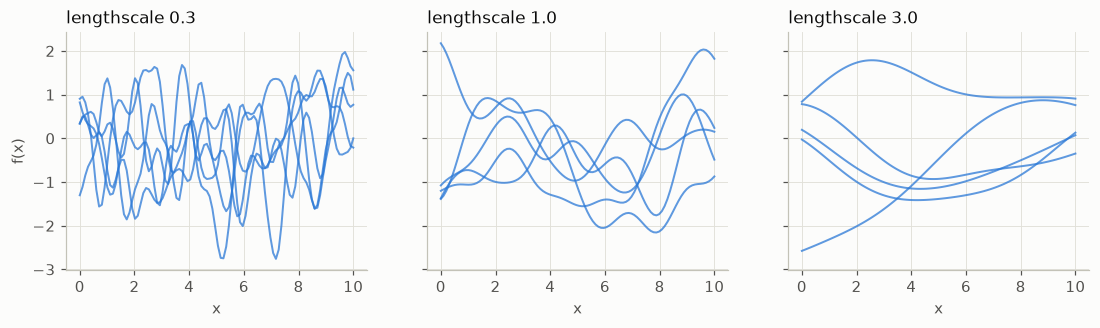

In [3]:
rng = np.random.default_rng(1)
fig, axes = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
for ax, ell in zip(axes, [0.3, 1.0, 3.0]):
    L = np.linalg.cholesky(gp_em.rbf_kernel(x_demo, x_demo, ell) + 1e-8 * np.eye(100))
    ax.plot(x_demo, L @ rng.standard_normal((100, 5)), color=C_F, lw=1.3, alpha=0.75)
    ax.set(title=f"lengthscale {ell}", xlabel="x")
axes[0].set_ylabel("f(x)");

## 2. The data

We never see $f$. We see it through noise:

$$y_i = f(x_i) + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal N(0, \sigma^2)$$

The model has two unknown parameters, $s^2$ (signal variance) and $\sigma^2$ (noise variance). The lengthscale is held fixed at its true value throughout to keep things simple.

We simulate data so that we know the truth and can check our answers.

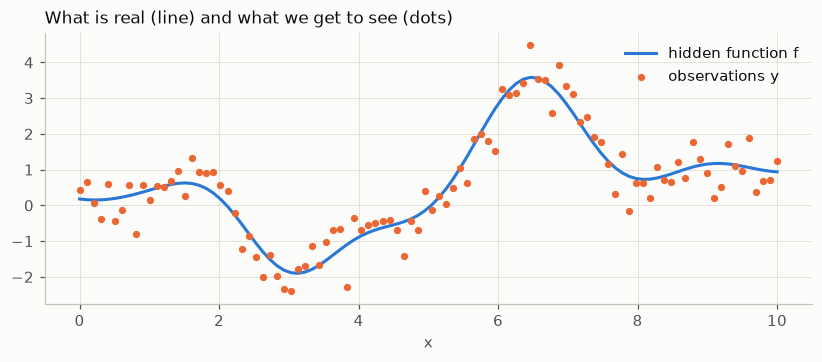

In [4]:
TRUE_S2, TRUE_SIGMA2, ELL = 2.0, 0.25, 1.0
x, f, y = gp_em.sample_data(n=100, s2=TRUE_S2, sigma2=TRUE_SIGMA2, lengthscale=ELL, seed=0)
K = gp_em.rbf_kernel(x, x, ELL)

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.plot(x, f, color=C_F, label="hidden function f")
ax.scatter(x, y, color=C_Y, s=14, zorder=3, label="observations y")
ax.set(title="What is real (line) and what we get to see (dots)", xlabel="x")
ax.legend();

## 3. GP regression when the parameters are known

Given $y$ and the parameters, what do we now believe about $f$? Because everything is Gaussian, the answer is another Gaussian, $f \mid y \sim \mathcal N(m, S)$, with

$$C = s^2K + \sigma^2 I, \qquad m = s^2 K\,C^{-1}y, \qquad S = s^2K - s^2K\,C^{-1}\,s^2K$$

$C$ is the covariance of $y$: signal plus noise. $m$ is our best estimate of $f$ and the diagonal of $S$ says how unsure we are at each point.

**This calculation is the E-step of EM.** Keep it in mind.

The catch is that $m$ depends heavily on the parameters. Left: the true parameters. Right: a poor guess that claims the signal is small and the noise is large, so the model explains the wiggles away as noise.

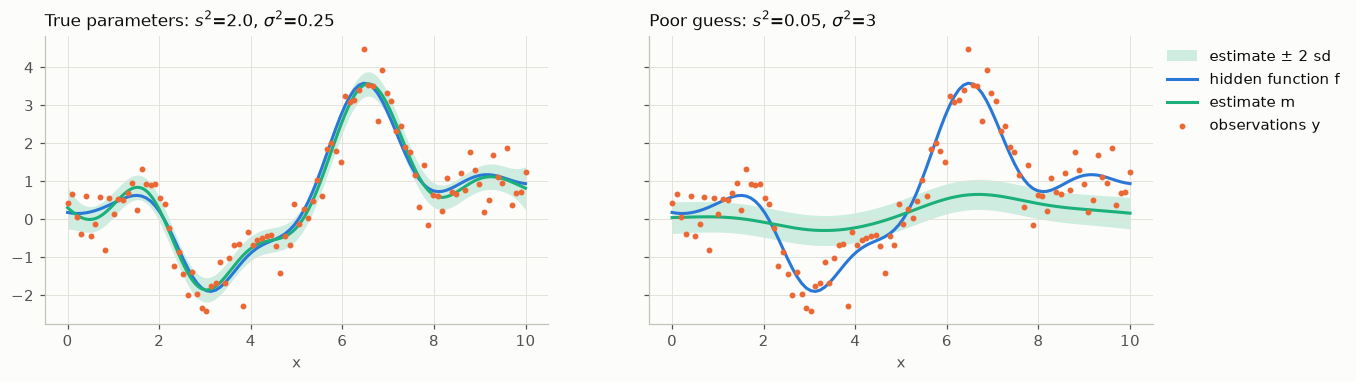

In [5]:
def plot_fit(ax, s2, sigma2, title):
    x_grid = np.linspace(0, 10, 300)
    mean, var = gp_em.predict(x, y, x_grid, s2, sigma2, ELL)
    sd = np.sqrt(np.maximum(var, 0))
    ax.fill_between(x_grid, mean - 2 * sd, mean + 2 * sd, color=C_POST, alpha=0.2, lw=0,
                    label="estimate ± 2 sd")
    ax.plot(x, f, color=C_F, label="hidden function f")
    ax.plot(x_grid, mean, color=C_POST, label="estimate m")
    ax.scatter(x, y, color=C_Y, s=8, zorder=3, label="observations y")
    ax.set(title=title, xlabel="x")

fig, axes = plt.subplots(1, 2, figsize=(13, 3.4), sharey=True)
plot_fit(axes[0], TRUE_S2, TRUE_SIGMA2, f"True parameters: $s^2$={TRUE_S2}, $\\sigma^2$={TRUE_SIGMA2}")
plot_fit(axes[1], 0.05, 3.0, "Poor guess: $s^2$=0.05, $\\sigma^2$=3")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.0, 1.0));

## 4. Why EM, and what the two steps are

We want the parameters that make the observed data most probable, i.e. that maximise the **marginal likelihood** $p(y \mid s^2, \sigma^2) = \mathcal N(y;\,0,\,C)$. "Marginal" because $f$ has been integrated out.

EM starts from an observation: **if someone handed us $f$, the problem would be trivial.**

- The noise is $y - f$, so $\sigma^2 = \frac1n \lVert y-f\rVert^2$ — the average squared residual.
- $f \sim \mathcal N(0, s^2K)$, so $s^2 = \frac1n f^\top K^{-1} f$ — the average squared value of $f$ after undoing its correlations.

We do not have $f$, but section 3 gave us a *distribution* for it. So we replace each quantity with its average over that distribution. For a Gaussian $f \sim \mathcal N(m, S)$ and any matrix $A$, $\;\mathbb E[f^\top A f] = m^\top A m + \operatorname{tr}(AS)$, which gives

$$\sigma^2_{\text{new}} = \frac{\lVert y-m\rVert^2 + \operatorname{tr}(S)}{n}, \qquad s^2_{\text{new}} = \frac{m^\top K^{-1}m + \operatorname{tr}(K^{-1}S)}{n}$$

Each update is "plug in the best guess $m$" plus a trace term that corrects for the fact that $m$ is smoother and smaller than the real $f$.

But $m$ and $S$ were computed using the *old* parameters. So we iterate:

- **E-step:** with the current parameters, compute the posterior $m, S$ of the hidden $f$.
- **M-step:** with that posterior, compute new parameters from the formulas above.

The formal justification (these updates maximise the expected complete-data log-likelihood $\mathbb E_{f\mid y}[\log p(y, f)]$) gives EM its guarantee: **the marginal likelihood can never go down from one iteration to the next.** That makes a very good bug detector.

## 5. Naive EM: the formulas exactly as written

`e_step_naive` and `m_step_naive` in `gp_em.py` transcribe the formulas literally, using `np.linalg.inv`. We try them first on an easy problem: 20 points and a short lengthscale.

EM after 165 iterations: s2 = 1.638, sigma2 = 0.084
direct optimiser:          s2 = 1.638, sigma2 = 0.084
truth:                     s2 = 2.000, sigma2 = 0.250


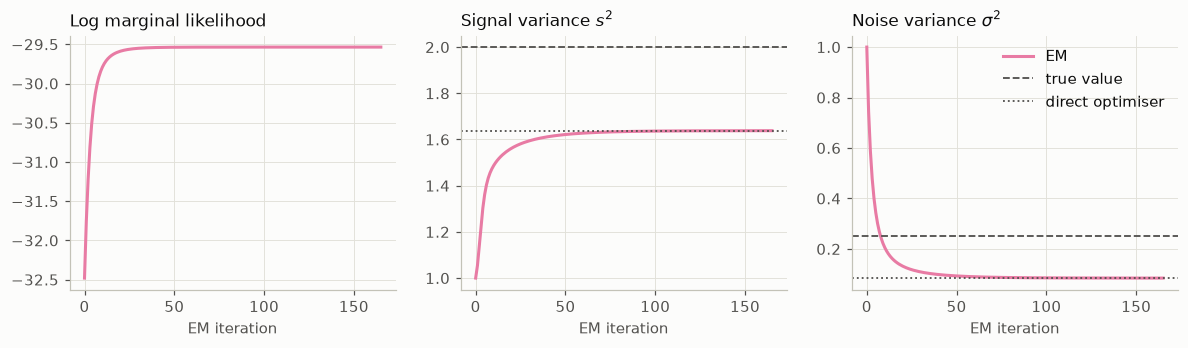

In [6]:
xs, fs, ys = gp_em.sample_data(n=20, s2=TRUE_S2, sigma2=TRUE_SIGMA2, lengthscale=0.5, seed=0)
Ks = gp_em.rbf_kernel(xs, xs, 0.5)

hist = gp_em.run_em(Ks, ys, s2_0=1.0, sigma2_0=1.0, naive=True)
s2_direct, sigma2_direct, ll_direct = gp_em.fit_direct(Ks, ys)
print(f"EM after {len(hist['s2']) - 1} iterations: s2 = {hist['s2'][-1]:.3f}, sigma2 = {hist['sigma2'][-1]:.3f}")
print(f"direct optimiser:          s2 = {s2_direct:.3f}, sigma2 = {sigma2_direct:.3f}")
print(f"truth:                     s2 = {TRUE_S2:.3f}, sigma2 = {TRUE_SIGMA2:.3f}")

def plot_history(hist, color, truth, best):
    fig, axes = plt.subplots(1, 3, figsize=(13, 3))
    axes[0].plot(hist["log_lik"], color=color)
    axes[0].set(title="Log marginal likelihood", xlabel="EM iteration")
    for ax, key, name in [(axes[1], "s2", "Signal variance $s^2$"), (axes[2], "sigma2", "Noise variance $\\sigma^2$")]:
        ax.plot(hist[key], color=color, label="EM")
        ax.axhline(truth[key], color=C_REF, lw=1.2, ls="--", label="true value")
        ax.axhline(best[key], color=C_REF, lw=1.2, ls=":", label="direct optimiser")
        ax.set(title=name, xlabel="EM iteration")
    axes[2].legend()

plot_history(hist, C_NAIVE, {"s2": TRUE_S2, "sigma2": TRUE_SIGMA2}, {"s2": s2_direct, "sigma2": sigma2_direct})

Three things to notice.

- The log-likelihood rises at every step, as promised.
- EM ends where the direct optimiser ends (dotted line). Both are finding the maximum of the same function.
- That maximum is **not the true value** (dashed line). Maximum likelihood gives the parameters that best explain *this one dataset*, and 20 noisy points do not pin the truth down. That is a property of the data, not a fault in EM.

## 6. Where the naive version breaks

Now the real dataset from section 2: 100 points, lengthscale 1.

naive EM final:  s2 = 2.3e-11, sigma2 = 2.45
stable EM final: s2 = 3.9, sigma2 = 0.214


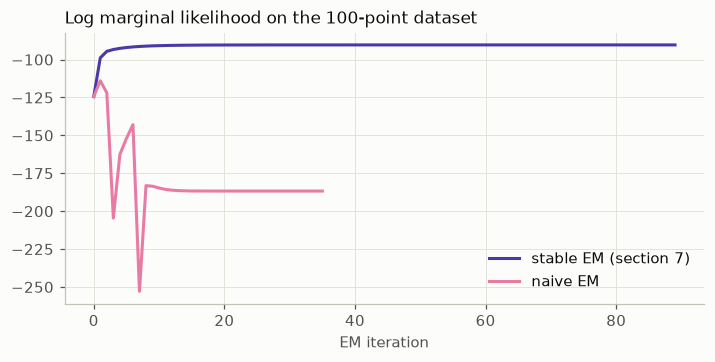

In [7]:
naive = gp_em.run_em(K, y, naive=True)
stable = gp_em.run_em(K, y)

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.plot(stable["log_lik"], color=C_STABLE, label="stable EM (section 7)")
ax.plot(naive["log_lik"], color=C_NAIVE, label="naive EM")
ax.set(title="Log marginal likelihood on the 100-point dataset", xlabel="EM iteration")
ax.legend()
print(f"naive EM final:  s2 = {naive['s2'][-1]:.3g}, sigma2 = {naive['sigma2'][-1]:.3g}")
print(f"stable EM final: s2 = {stable['s2'][-1]:.3g}, sigma2 = {stable['sigma2'][-1]:.3g}")

The naive likelihood goes **down**. EM cannot do that, so the code is computing something other than the formula it appears to compute. The formulas are right; the arithmetic is not.

The culprit is `np.linalg.inv(K)` in the M-step. Neighbouring points are so strongly correlated that neighbouring rows of $K$ are nearly identical, which makes $K$ almost singular. The **condition number** measures this: roughly, inverting a matrix with condition number $10^k$ loses $k$ of the 16 decimal digits a double holds.

cond(K) for our dataset: 7.8e+19
largest entry of |K @ inv(K) - I|: 14   (should be ~1e-16)


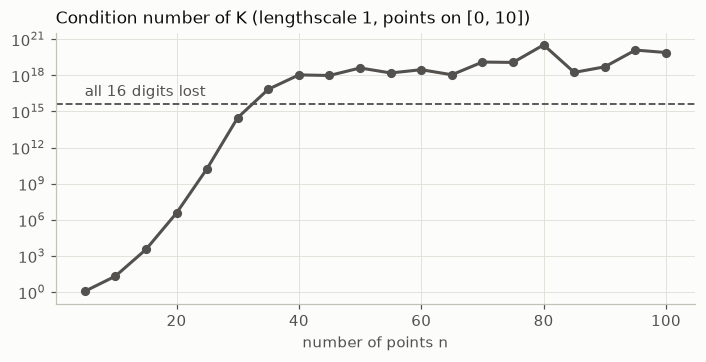

In [8]:
sizes = np.arange(5, 101, 5)
conds = [np.linalg.cond(gp_em.rbf_kernel(np.linspace(0, 10, n), np.linspace(0, 10, n), ELL)) for n in sizes]

fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.semilogy(sizes, conds, color=C_REF, marker="o", ms=5)
ax.axhline(1 / np.finfo(float).eps, color=C_REF, lw=1.2, ls="--")
ax.annotate("all 16 digits lost", (5, 1 / np.finfo(float).eps), xytext=(0, 5), textcoords="offset points", color=C_REF)
ax.set(title="Condition number of K (lengthscale 1, points on [0, 10])", xlabel="number of points n")

K_inv = np.linalg.inv(K)
print(f"cond(K) for our dataset: {np.linalg.cond(K):.1e}")
print(f"largest entry of |K @ inv(K) - I|: {np.abs(K @ K_inv - np.eye(100)).max():.2g}   (should be ~1e-16)")

By about 35 points the "inverse" NumPy returns is noise. NumPy does not raise an error; it returns a matrix of plausible-looking numbers. The only reason we noticed is that we were tracking a quantity with a known invariant.

## 7. Stable EM: same maths, no $K^{-1}$

Two separate fixes.

**Fix 1: algebra.** $K^{-1}$ appears only in the $s^2$ update, and it can be cancelled on paper. Write $\alpha = C^{-1}y$.

- Since $m = s^2K\alpha$: $\quad m^\top K^{-1} m = s^2\,\alpha^\top m$
- Since $S = s^2K - s^4KC^{-1}K$: $\quad \operatorname{tr}(K^{-1}S) = n s^2 - s^4\operatorname{tr}(C^{-1}K)$

Now the only matrix we need to "invert" is $C = s^2K + \sigma^2I$. Adding $\sigma^2 I$ lifts every eigenvalue by $\sigma^2$, so $C$ is well conditioned even though $K$ is not.

**Fix 2: never form an inverse at all.** To get $C^{-1}y$, factor $C = LL^\top$ with $L$ lower triangular (Cholesky), then solve two triangular systems. That is faster and more accurate than `inv`, and the same factor gives the log-determinant for free: $\log\lvert C\rvert = 2\sum_i \log L_{ii}$.

That is `e_step` and `m_step` in `gp_em.py`.

cond(K) = 7.8e+19     cond(C) = 1.9e+02
stable EM after 89 iterations: s2 = 3.898, sigma2 = 0.214
direct optimiser:              s2 = 3.899, sigma2 = 0.214
truth:                         s2 = 2.000, sigma2 = 0.250


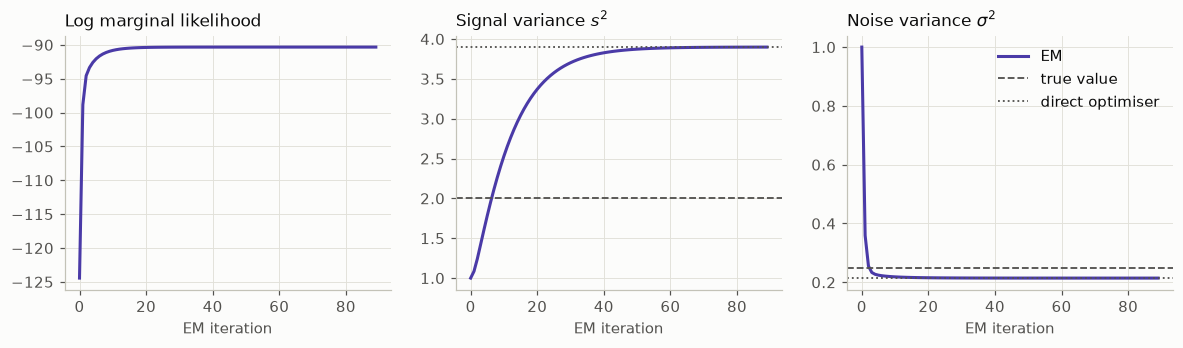

In [9]:
C_now = TRUE_S2 * K + TRUE_SIGMA2 * np.eye(100)
print(f"cond(K) = {np.linalg.cond(K):.1e}     cond(C) = {np.linalg.cond(C_now):.1e}")

s2_direct, sigma2_direct, ll_direct = gp_em.fit_direct(K, y)
print(f"stable EM after {len(stable['s2']) - 1} iterations: s2 = {stable['s2'][-1]:.3f}, sigma2 = {stable['sigma2'][-1]:.3f}")
print(f"direct optimiser:              s2 = {s2_direct:.3f}, sigma2 = {sigma2_direct:.3f}")
print(f"truth:                         s2 = {TRUE_S2:.3f}, sigma2 = {TRUE_SIGMA2:.3f}")

plot_history(stable, C_STABLE, {"s2": TRUE_S2, "sigma2": TRUE_SIGMA2}, {"s2": s2_direct, "sigma2": sigma2_direct})

The likelihood is monotone again and EM agrees with the direct optimiser.

Look at how differently the two parameters are recovered. $\sigma^2$ lands close to the truth: there are 100 independent noise values to estimate it from. $s^2$ is well off: a function with lengthscale 1 on an interval of length 10 only has room for a handful of independent wiggles, so this dataset contains very little information about how tall wiggles are *on average*. Both EM and the optimiser correctly report the best-fitting value; the data simply cannot do better.

The fitted model still reconstructs $f$ well, because the estimate $m$ depends mostly on the ratio of signal to noise locally:

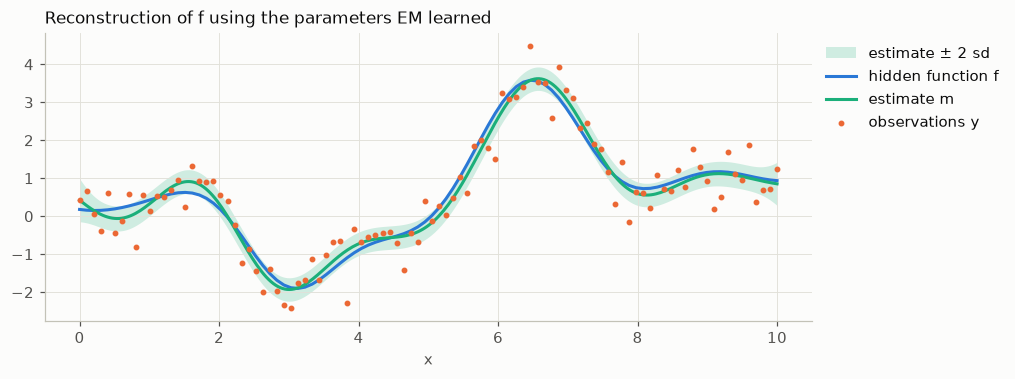

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.4))
plot_fit(ax, stable["s2"][-1], stable["sigma2"][-1], "Reconstruction of f using the parameters EM learned")
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0));

## 8. EM versus direct optimisation

With only two parameters we can draw the whole likelihood surface and watch EM climb it.

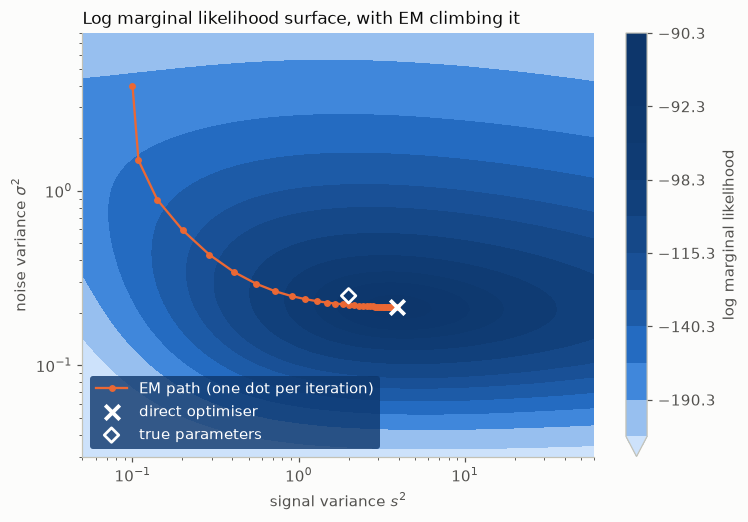

In [11]:
log_s2_grid = np.linspace(np.log(0.05), np.log(60), 70)
log_sigma2_grid = np.linspace(np.log(0.03), np.log(8), 70)
surface = np.array([[gp_em.log_marginal_likelihood(K, y, np.exp(a), np.exp(b)) for a in log_s2_grid]
                    for b in log_sigma2_grid])

path = gp_em.run_em(K, y, s2_0=0.1, sigma2_0=4.0, n_iter=5000, tol=1e-12)

fig, ax = plt.subplots(figsize=(7.5, 5))
levels = surface.max() - np.array([150, 100, 70, 50, 35, 25, 15, 8, 4, 2, 0.5, 0])
cs = ax.contourf(np.exp(log_s2_grid), np.exp(log_sigma2_grid), surface, levels=levels, cmap=BLUES, extend="min")
ax.plot(path["s2"], path["sigma2"], color=C_Y, lw=1.5, marker="o", ms=3.5, label="EM path (one dot per iteration)")
ax.scatter([s2_direct], [sigma2_direct], marker="x", s=90, color="white", linewidths=2.5, zorder=5, label="direct optimiser")
ax.scatter([TRUE_S2], [TRUE_SIGMA2], marker="D", s=45, facecolor="none", edgecolor="white", linewidths=1.8, zorder=5, label="true parameters")
ax.set(xscale="log", yscale="log", xlabel="signal variance $s^2$", ylabel="noise variance $\\sigma^2$",
       title="Log marginal likelihood surface, with EM climbing it")
ax.grid(False)
fig.colorbar(cs, ax=ax, label="log marginal likelihood")
leg = ax.legend(loc="lower left", frameon=True, facecolor="#0d366b", edgecolor="none", labelcolor="white")

EM takes large steps while it is far away and shorter and shorter ones as it approaches the top. The ridge is long in the $s^2$ direction: that elongated shape is the "little information about $s^2$" from section 7, drawn as a picture.

How fast does it close the remaining gap?

EM iterations until the gap is below 1e-6: 81


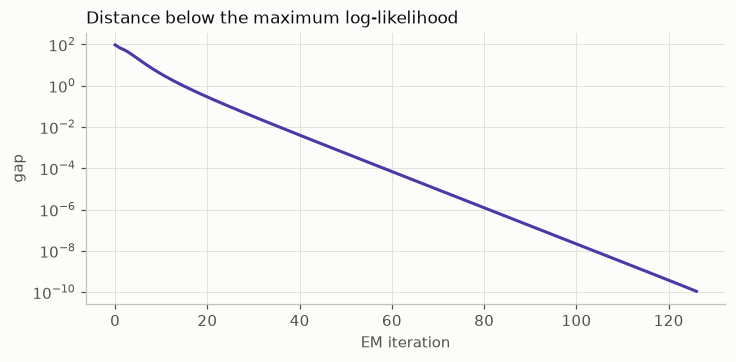

In [12]:
best = max(path["log_lik"][-1], ll_direct)
gap = best - np.array(path["log_lik"])

fig, ax = plt.subplots(figsize=(7.5, 3.2))
keep = gap > 1e-10  # below this the gap is rounding error in the log-likelihood itself
ax.semilogy(np.arange(len(gap))[keep], gap[keep], color=C_STABLE)
ax.set(title="Distance below the maximum log-likelihood", xlabel="EM iteration", ylabel="gap")
print(f"EM iterations until the gap is below 1e-6: {int(np.argmax(gap < 1e-6))}")

A straight line on a log scale means each iteration removes a fixed *fraction* of the remaining error (linear convergence). Optimisers such as L-BFGS use curvature information and typically speed up near the optimum instead.

There is a neat reason EM behaves this way here. Rearranging the stable M-step shows that it is a gradient step on the marginal likelihood $\mathcal L$ with a built-in step size:

$$s^2_{\text{new}} = s^2 + \frac{2 s^4}{n}\,\frac{\partial \mathcal L}{\partial s^2}, \qquad \sigma^2_{\text{new}} = \sigma^2 + \frac{2\sigma^4}{n}\,\frac{\partial \mathcal L}{\partial \sigma^2}$$

We can check that numerically with a finite-difference gradient:

In [13]:
s2_0, sigma2_0, h = 1.3, 0.7, 1e-6
m, S, alpha, C_inv_K = gp_em.e_step(K, y, s2_0, sigma2_0)
s2_em, sigma2_em = gp_em.m_step(y, m, S, alpha, C_inv_K, s2_0)

ll = lambda a, b: gp_em.log_marginal_likelihood(K, y, a, b)
grad_s2 = (ll(s2_0 + h, sigma2_0) - ll(s2_0 - h, sigma2_0)) / (2 * h)
grad_sigma2 = (ll(s2_0, sigma2_0 + h) - ll(s2_0, sigma2_0 - h)) / (2 * h)

n = len(y)
print(f"s2:     M-step {s2_em:.8f}   gradient step {s2_0 + 2 * s2_0**2 / n * grad_s2:.8f}")
print(f"sigma2: M-step {sigma2_em:.8f}   gradient step {sigma2_0 + 2 * sigma2_0**2 / n * grad_sigma2:.8f}")

s2:     M-step 1.39761360   gradient step 1.39761360
sigma2: M-step 0.30400960   gradient step 0.30400960


So what does EM buy you? No step size to tune, parameters that stay positive automatically, and a guaranteed increase every iteration. What it costs is speed near the optimum. For GPs in practice people usually use a gradient-based optimiser on the marginal likelihood; EM earns its keep in models where the M-step is easy but the marginal likelihood is awkward (mixture models, hidden Markov models, state-space models).

## 9. Where next

**Learning the lengthscale.** $\ell$ sits inside $K$ non-linearly, so there is no closed-form M-step for it. The usual answer is *generalised EM*: do a one-dimensional numerical search for $\ell$ inside the M-step, improving the objective rather than maximising it exactly.

**Porting to C or C++.** The whole algorithm reduces to four primitives, each a good exercise to write by hand and then compare against LAPACK:

| Primitive | Used for | LAPACK routine |
|---|---|---|
| Cholesky factorisation $C = LL^\top$ | everything | `dpotrf` |
| Triangular solve | $\alpha = C^{-1}y$ and $C^{-1}K$ | `dtrsv` / `dpotrs` |
| Log-determinant from $\operatorname{diag}(L)$ | the likelihood | a loop |
| Trace of a product | the M-step | a loop |

The checks in `checks/` are written against behaviour (invariants, agreement with references), so the same checks can be reused to validate a C++ port.